# PD05 · Particionamiento y comparación pandas–Polars

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 210 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, Polars y GeoPandas. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y preparación

¿Cómo cambian lectura, escritura y procesamiento al variar formato, particionamiento y motor?

Requiere el Parquet completo y la capa municipal del GeoPackage de PD04 y las dependencias del entorno del curso: `requirements.txt` y `requirements_pqrs.txt`. Trabaja en CPU. No dupliques filas para simular volumen. Esta actividad estudia los resultados de este equipo y estos datos.

Las lecturas siguientes son directas. Para comparar CSV más adelante, escribe explícitamente `pd.read_csv` y `pl.read_csv`, sus separadores, política de nulos y tipos. No uses inferencia diferente de tipos como si fuera trabajo equivalente.

El particionamiento será manual: un `groupby` divide la tabla y cada grupo se escribe en un archivo independiente. Los valores de las claves permanecen dentro de cada archivo. Un inventario CSV registra dónde está cada parte; no se configura un catálogo ni un motor de particiones.


In [1]:
import os
import time
import platform
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
INPUT = REPO + "/kit/salidas/soluciones/PD04/analisis_integrados.parquet"
OUT = REPO + "/kit/salidas/soluciones/PD05"
os.makedirs(OUT, exist_ok=True)
print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print("pandas:", pd.__version__, "Polars:", pl.__version__, "GeoPandas:", gpd.__version__)

Entrada: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 2.2.3 Polars: 1.35.2 GeoPandas: 1.2.0


In [2]:
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
display(datos_pd.head())
print(datos_pd.shape)
print(datos_pd.dtypes)

,id_fila,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,...,longitud,Latitud,longitud_territorial,latitud_territorial,longitud_num,longitud_error_conversion,Latitud_num,Latitud_error_conversion,_merge,estado_union
0,0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,...,"-78,764073","1,807399",-78.764073,1.807399,-78.764073,False,1.807399,False,both,coincidencia
1,1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,...,"-75,586223","2,939603",-75.586223,2.939603,-75.586223,False,2.939603,False,both,coincidencia
2,2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,...,"-75,812838","6,677316",-75.812838,6.677316,-75.812838,False,6.677316,False,both,coincidencia
3,3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,...,"-75,812838","6,677316",-75.812838,6.677316,-75.812838,False,6.677316,False,both,coincidencia
4,4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,...,"-75,812838","6,677316",-75.812838,6.677316,-75.812838,False,6.677316,False,both,coincidencia


(92738, 54)
id_fila                                        int64
Secuencial                                    object
Fecha de Análisis                             object
Departamento                                  object
Municipio                                     object
Cultivo                                       object
Estado                                        object
Tiempo de establecimiento                     object
Topografia                                    object
Drenaje                                       object
Riego                                         object
Fertilizantes aplicados                       object
pH agua:suelo                                 object
Materia organica                              object
Fósforo Bray II                               object
Azufre Fosfato monocalcico                    object
Acidez Intercambiable                         object
Aluminio intercambiable                       object
Calcio intercambiable             

In [3]:
datos_pl = pl.read_parquet(INPUT)
print(datos_pl.head())
print(datos_pl.shape)
print(datos_pl.schema)

shape: (5, 54)
┌─────────┬────────────┬────────────┬────────────┬───┬────────────┬───────────┬────────┬───────────┐
│ id_fila ┆ Secuencial ┆ Fecha de   ┆ Departamen ┆ … ┆ Latitud_nu ┆ Latitud_e ┆ _merge ┆ estado_un │
│ ---     ┆ ---        ┆ Análisis   ┆ to         ┆   ┆ m          ┆ rror_conv ┆ ---    ┆ ion       │
│ i64     ┆ str        ┆ ---        ┆ ---        ┆   ┆ ---        ┆ ersion    ┆ cat    ┆ ---       │
│         ┆            ┆ str        ┆ str        ┆   ┆ f64        ┆ ---       ┆        ┆ str       │
│         ┆            ┆            ┆            ┆   ┆            ┆ bool      ┆        ┆           │
╞═════════╪════════════╪════════════╪════════════╪═══╪════════════╪═══════════╪════════╪═══════════╡
│ 0       ┆ 1          ┆ 7/01/2014  ┆ NARIÑO     ┆ … ┆ 1.807399   ┆ false     ┆ both   ┆ coinciden │
│         ┆            ┆            ┆            ┆   ┆            ┆           ┆        ┆ cia       │
│ 1       ┆ 2          ┆ 21/08/2014 ┆ HUILA      ┆ … ┆ 2.939603   ┆ false   

## 1. Contrato común y consulta · 25 minutos

Proyecta en ambos motores las mismas columnas: `id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph` y `ph_valido`. Mantén todas las filas. Declara tipos equivalentes, cómo representar nulos en CSV y cómo restaurar códigos con ceros iniciales.

Elige un año y departamento presentes. Filtra y agrupa por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. Conserva el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos. En pandas utiliza `groupby(..., dropna=False)`; en Polars comprueba el tratamiento equivalente de claves nulas.

**Control:** compara claves y conteos exactos; medias con tolerancia absoluta 0.000001 y relativa cero. Ordena antes de comparar y comprueba también dónde aparecen nulos.

In [4]:
# Desarrollo
# Prepara la proyección común e implementa la consulta en ambos motores.
print("Columnas pandas:")
print(datos_pd.columns.tolist())

print("\nColumnas Polars:")
print(datos_pl.columns)

Columnas pandas:
['id_fila', 'Secuencial', 'Fecha de Análisis', 'Departamento', 'Municipio', 'Cultivo', 'Estado', 'Tiempo de establecimiento', 'Topografia', 'Drenaje', 'Riego', 'Fertilizantes aplicados', 'pH agua:suelo', 'Materia organica', 'Fósforo Bray II', 'Azufre Fosfato monocalcico', 'Acidez Intercambiable', 'Aluminio intercambiable', 'Calcio intercambiable', 'Magnesio intercambiable', 'Potasio intercambiable', 'Sodio intercambiable', 'capacidad de intercambio cationico', 'Conductividad electrica', 'Hierro disponible olsen', 'Cobre disponible', 'Manganeso disponible Olsen', 'Zinc disponible Olsen', 'Boro disponible', 'Hierro disponible doble acido', 'Cobre disponible doble acido', 'Manganeso disponible doble acido', 'Zinc disponible doble \xa0acido', 'fecha_dt', 'anio', 'ph', 'ph_valido', '_depto', '_municipio', 'clave_completa', 'Código Departamento', 'Código Municipio', 'Nombre Departamento', 'Nombre Municipio', 'longitud', 'Latitud', 'longitud_territorial', 'latitud_territorial

In [5]:
columnas = [
    "id_fila",
    "anio",
    "Código Departamento",
    "Código Municipio",
    "ph",
    "ph_valido",
]

faltan_pd = set(columnas) - set(datos_pd.columns)
faltan_pl = set(columnas) - set(datos_pl.columns)

assert not faltan_pd, f"Faltan en pandas: {faltan_pd}"
assert not faltan_pl, f"Faltan en Polars: {faltan_pl}"

# Proyección: se conservan todas las filas.
base_pd = datos_pd.loc[:, columnas].copy()
base_pl = datos_pl.select(columnas)

print("Pandas:", base_pd.shape)
print("Polars:", base_pl.shape)

assert len(base_pd) == base_pl.height
#---------------------------
# Pandas
base_pd["id_fila"] = base_pd["id_fila"].astype("Int64")
base_pd["anio"] = base_pd["anio"].astype("Int64")

for col in ["Código Departamento", "Código Municipio"]:
    base_pd[col] = base_pd[col].astype("string")

base_pd["ph"] = base_pd["ph"].astype("float64")
base_pd["ph_valido"] = base_pd["ph_valido"].astype("boolean")

# Polars
base_pl = base_pl.with_columns([
    pl.col("id_fila").cast(pl.Int64),
    pl.col("anio").cast(pl.Int64),
    pl.col("Código Departamento").cast(pl.String),
    pl.col("Código Municipio").cast(pl.String),
    pl.col("ph").cast(pl.Float64),
    pl.col("ph_valido").cast(pl.Boolean),
])

print(base_pd.dtypes)
print(base_pl.schema)
print("------------------")
combinaciones = (
    base_pd.loc[
        base_pd["anio"].notna()
        & base_pd["Código Departamento"].notna(),
        ["anio", "Código Departamento"],
    ]
    .drop_duplicates()
    .sort_values(["anio", "Código Departamento"])
)

assert not combinaciones.empty
display(combinaciones)
anio_elegido = int(combinaciones.iloc[0]["anio"])
depto_elegido = combinaciones.iloc[0]["Código Departamento"]

print("Año:", anio_elegido)
print("Departamento:", depto_elegido)

filtro_pd = base_pd.loc[
    (base_pd["anio"] == anio_elegido)
    & (base_pd["Código Departamento"] == depto_elegido)
].copy()

filtro_pl = base_pl.filter(
    (pl.col("anio") == anio_elegido)
    & (pl.col("Código Departamento") == depto_elegido)
)

assert len(filtro_pd) == filtro_pl.height
#----------------------
# Pandas: dropna=False conserva el grupo de municipio nulo.
resumen_pd = (
    filtro_pd.groupby("Código Municipio", dropna=False)
    .agg(
        total_analisis=("id_fila", "size"),
        cantidad_ph_validos=(
            "ph_valido",
            lambda s: int(s.fillna(False).sum()),
        ),
        media_ph_valido=(
            "ph",
            lambda s: s[
                filtro_pd.loc[s.index, "ph_valido"]
                .fillna(False)
                .astype("boolean")
            ].mean(),
        ),
    )
    .reset_index()
)

# Polars: group_by incluye las claves nulas.
resumen_pl = (
    filtro_pl.group_by("Código Municipio")
    .agg(
        pl.len().alias("total_analisis"),
        pl.col("ph_valido")
        .fill_null(False)
        .cast(pl.Int64)
        .sum()
        .alias("cantidad_ph_validos"),
        pl.col("ph")
        .filter(pl.col("ph_valido").fill_null(False))
        .mean()
        .alias("media_ph_valido"),
    )
    .sort("Código Municipio", nulls_last=True)
)

display(resumen_pd)
display(resumen_pl)
#------------------------------------
comparacion_pl = resumen_pl.to_pandas()

def preparar(df):
    df = df.copy()
    df["_clave"] = (
        df["Código Municipio"]
        .astype("string")
        .fillna("<NULO>")
    )
    return df.sort_values("_clave").reset_index(drop=True)

a = preparar(resumen_pd)
b = preparar(comparacion_pl)

assert a["_clave"].equals(b["_clave"])

for col in ["total_analisis", "cantidad_ph_validos"]:
    assert (a[col].to_numpy() == b[col].to_numpy()).all(), (
        f"Diferencias en {col}"
    )

assert a["Código Municipio"].isna().equals(
    b["Código Municipio"].isna()
)

assert a["media_ph_valido"].isna().equals(
    b["media_ph_valido"].isna()
)

import numpy as np

np.testing.assert_allclose(
    a["media_ph_valido"].to_numpy(dtype=float),
    b["media_ph_valido"].to_numpy(dtype=float),
    atol=0.000001,
    rtol=0,
    equal_nan=True,
)


Pandas: (92738, 6)
Polars: (92738, 6)
id_fila                         Int64
anio                            Int64
Código Departamento    string[python]
Código Municipio       string[python]
ph                            float64
ph_valido                     boolean
dtype: object
Schema({'id_fila': Int64, 'anio': Int64, 'Código Departamento': String, 'Código Municipio': String, 'ph': Float64, 'ph_valido': Boolean})
------------------


,anio,Código Departamento
2,2014,05
1032,2014,08
833,2014,11
211,2014,13
78,2014,15
...,...,...
90068,2025,85
90133,2025,86
90346,2025,91
90287,2025,95


Año: 2014
Departamento: 05


,Código Municipio,total_analisis,cantidad_ph_validos,media_ph_valido
0,05001,13,13,4.675385
1,05045,1,1,5.870000
2,05079,1,1,5.220000
3,05134,1,1,4.860000
4,05142,1,1,5.600000
5,05237,10,10,4.765900
6,05264,9,9,5.011000
7,05284,1,1,4.519000
8,05306,1,1,6.490000
9,05318,2,2,6.255000


Código Municipio,total_analisis,cantidad_ph_validos,media_ph_valido
str,u32,i64,f64
"""05001""",13,13,4.675385
"""05045""",1,1,5.87
"""05079""",1,1,5.22
"""05134""",1,1,4.86
"""05142""",1,1,5.6
…,…,…,…
"""05809""",1,1,5.83
"""05837""",1,1,5.54
"""05847""",10,10,5.418


**Interpretación:**

_Se proyectaron en pandas y polars, las mismas columnas:id_fila, anio, codigo_departamento, codigo_municipio, ph y ph_valido.Luego se declararon tipos equivalentes y se eligio el año 2014 y el departamento de codigo "05". Posteriormente,se filtro y agrupo por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido.Tambien se conservo el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos._

_Con las tablas se pudo comprobar que salen los mismo resultados en los dos motores._

## 2. Particionamiento manual desde pandas · 35 minutos

Escribe la misma proyección como CSV y Parquet único. Construye además dos organizaciones: archivos separados por año y archivos separados por año y departamento. Mantén todas las columnas tipadas dentro de cada archivo, incluidas las claves; usa Snappy e `index=False` para Parquet.

Usa `groupby(..., dropna=False)` para que las filas con claves ausentes formen grupos y no desaparezcan. Escribe cada grupo con una llamada directa a `to_parquet`. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial. Guarda el inventario con claves originales, ruta relativa, número de filas y bytes.

Este ejemplo muestra la mecánica por año. Adáptalo también a año y departamento, en otra carpeta. `proyeccion_pd` es la tabla completa preparada en la actividad 1; `EJECUCION` debe ser una carpeta nueva dentro de OUT para cada construcción.

```python
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
```

Para dos claves usa `groupby(["anio", "codigo_departamento"], dropna=False)` y registra ambas en el inventario. Muestra su código completo. Al releer el inventario, usa `pd.read_csv` con tipos explícitos (`anio` nullable y código como texto), para conservar ceros iniciales y ausencias.

**Control:** relee todos los archivos por ruta, concatena con `pd.concat(..., ignore_index=True)` y compara con la proyección ordenada por `id_fila`. Comprueba unicidad y conservación de IDs, no solo el total. Compara archivos pequeños, cantidad y bytes entre ambos diseños. Dividir archivos no implica procesamiento paralelo.

In [6]:
# Desarrollo
# Escribe las cuatro representaciones y presenta su inventario de particiones.

import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow  # Motor Parquet

OUT = Path("OUT")
OUT.mkdir(parents=True, exist_ok=True)

EJECUCION = OUT / "EJECUCION"
EJECUCION.mkdir(parents=True, exist_ok=True)


columnas = [
    "id_fila",
    "anio",
    "Código Departamento",
    "Código Municipio",
    "ph",
    "ph_valido",
]

# Copia de la proyección completa de la actividad 1.
proyeccion_pd = datos_pd.loc[:, columnas].copy()

# Contrato de tipos común a todos los archivos.
proyeccion_pd["id_fila"] = proyeccion_pd["id_fila"].astype("Int64")
proyeccion_pd["anio"] = proyeccion_pd["anio"].astype("Int64")

proyeccion_pd["Código Departamento"] = (
    proyeccion_pd["Código Departamento"].astype("string")
)
proyeccion_pd["Código Municipio"] = (
    proyeccion_pd["Código Municipio"].astype("string")
)

proyeccion_pd["ph"] = proyeccion_pd["ph"].astype("float64")
proyeccion_pd["ph_valido"] = (
    proyeccion_pd["ph_valido"].astype("boolean")
)

# Validaciones básicas.
assert proyeccion_pd["id_fila"].notna().all()
assert proyeccion_pd["id_fila"].is_unique
assert proyeccion_pd.columns.tolist() == columnas

print("Ejecución:", EJECUCION)
print("Filas:", len(proyeccion_pd))
print("Tipos:")
print(proyeccion_pd.dtypes)
#--------------------

# CSV completo.
archivo_csv = EJECUCION / "proyeccion_completa.csv"

proyeccion_pd.to_csv(
    archivo_csv,
    index=False,
    na_rep=r"\N",
    encoding="utf-8",
)

# Parquet completo.
archivo_parquet = EJECUCION / "proyeccion_completa.parquet"

proyeccion_pd.to_parquet(
    archivo_parquet,
    engine="pyarrow",
    compression="snappy",
    index=False,
)

print("CSV:", archivo_csv.stat().st_size, "bytes")
print("Parquet:", archivo_parquet.stat().st_size, "bytes")
#----------------

carpeta_anio = EJECUCION / "por_anio"
# carpeta_anio.mkdir(parents=True, exist_ok=False)

inventario = []

for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby(
        "anio",
        dropna=False,
        sort=True,
    )
):
    archivo = carpeta_anio / f"parte-{numero:04d}.parquet"

    grupo.to_parquet(
        archivo,
        engine="pyarrow",
        compression="snappy",
        index=False,
    )

    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })

inventario_anio = pd.DataFrame(
    inventario,
    columns=["anio", "archivo", "filas", "bytes"],
)

ruta_inventario_anio = EJECUCION / "inventario_anio.csv"

inventario_anio.to_csv(
    ruta_inventario_anio,
    index=False,
    na_rep=r"\N",
    encoding="utf-8",
)

display(inventario_anio)
print("Partes por año:", len(inventario_anio))
#-----------------------

carpeta_anio_depto = EJECUCION / "por_anio_departamento"
#carpeta_anio_depto.mkdir(parents=True, exist_ok=False)

inventario = []

for numero, ((anio, departamento), grupo) in enumerate(
    proyeccion_pd.groupby(
        ["anio", "Código Departamento"],
        dropna=False,
        sort=True,
    )
):
    archivo = carpeta_anio_depto / f"parte-{numero:04d}.parquet"

    grupo.to_parquet(
        archivo,
        engine="pyarrow",
        compression="snappy",
        index=False,
    )

    inventario.append({
        "anio": anio,
        "Código Departamento": departamento,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })

inventario_anio_depto = pd.DataFrame(
    inventario,
    columns=[
        "anio",
        "Código Departamento",
        "archivo",
        "filas",
        "bytes",
    ],
)

ruta_inventario_anio_depto = (
    EJECUCION / "inventario_anio_departamento.csv"
)

inventario_anio_depto.to_csv(
    ruta_inventario_anio_depto,
    index=False,
    na_rep=r"\N",
    encoding="utf-8",
)

display(inventario_anio_depto)
print("Partes por año y departamento:", len(inventario_anio_depto))
#-------------------------------

# El marcador \N se interpreta como nulo.
opciones_csv = {
    "na_values": [r"\N"],
    "keep_default_na": False,
    "encoding": "utf-8",
}

inventario_anio_leido = pd.read_csv(
    ruta_inventario_anio,
    dtype={
        "anio": "Int64",
        "archivo": "string",
        "filas": "Int64",
        "bytes": "Int64",
    },
    **opciones_csv,
)

inventario_anio_depto_leido = pd.read_csv(
    ruta_inventario_anio_depto,
    dtype={
        "anio": "Int64",
        "codigo_departamento": "string",
        "archivo": "string",
        "filas": "Int64",
        "bytes": "Int64",
    },
    **opciones_csv,
)

print("Tipos del inventario por año:")
print(inventario_anio_leido.dtypes)

print("\nTipos del inventario por año y departamento:")
print(inventario_anio_depto_leido.dtypes)

display(inventario_anio_leido)
display(inventario_anio_depto_leido)
#-----------------------


Ejecución: OUT/EJECUCION
Filas: 92738
Tipos:
id_fila                         Int64
anio                            Int64
Código Departamento    string[python]
Código Municipio       string[python]
ph                            float64
ph_valido                     boolean
dtype: object
CSV: 2757904 bytes
Parquet: 830579 bytes


,anio,archivo,filas,bytes
0,2014,por_anio/parte-0000.parquet,10886,96742
1,2015,por_anio/parte-0001.parquet,13228,117871
2,2016,por_anio/parte-0002.parquet,14539,130869
3,2017,por_anio/parte-0003.parquet,7655,72373
4,2018,por_anio/parte-0004.parquet,4208,42261
5,2019,por_anio/parte-0005.parquet,5983,57790
6,2020,por_anio/parte-0006.parquet,5048,50660
7,2021,por_anio/parte-0007.parquet,7229,68725
8,2022,por_anio/parte-0008.parquet,9784,88540
9,2023,por_anio/parte-0009.parquet,7847,71526


Partes por año: 12


,anio,Código Departamento,archivo,filas,bytes
0,2014,05,por_anio_departamento/parte-0000.parquet,517,8407
1,2014,08,por_anio_departamento/parte-0001.parquet,16,4091
2,2014,11,por_anio_departamento/parte-0002.parquet,24,4112
3,2014,13,por_anio_departamento/parte-0003.parquet,192,5542
4,2014,15,por_anio_departamento/parte-0004.parquet,484,8199
...,...,...,...,...,...
368,2025,86,por_anio_departamento/parte-0368.parquet,58,4491
369,2025,91,por_anio_departamento/parte-0369.parquet,13,4004
370,2025,95,por_anio_departamento/parte-0370.parquet,4,3903
371,2025,99,por_anio_departamento/parte-0371.parquet,26,4164


Partes por año y departamento: 373
Tipos del inventario por año:
anio                Int64
archivo    string[python]
filas               Int64
bytes               Int64
dtype: object

Tipos del inventario por año y departamento:
anio                            Int64
Código Departamento           float64
archivo                string[python]
filas                           Int64
bytes                           Int64
dtype: object


,anio,archivo,filas,bytes
0,2014,por_anio/parte-0000.parquet,10886,96742
1,2015,por_anio/parte-0001.parquet,13228,117871
2,2016,por_anio/parte-0002.parquet,14539,130869
3,2017,por_anio/parte-0003.parquet,7655,72373
4,2018,por_anio/parte-0004.parquet,4208,42261
5,2019,por_anio/parte-0005.parquet,5983,57790
6,2020,por_anio/parte-0006.parquet,5048,50660
7,2021,por_anio/parte-0007.parquet,7229,68725
8,2022,por_anio/parte-0008.parquet,9784,88540
9,2023,por_anio/parte-0009.parquet,7847,71526


,anio,Código Departamento,archivo,filas,bytes
0,2014,5.0,por_anio_departamento/parte-0000.parquet,517,8407
1,2014,8.0,por_anio_departamento/parte-0001.parquet,16,4091
2,2014,11.0,por_anio_departamento/parte-0002.parquet,24,4112
3,2014,13.0,por_anio_departamento/parte-0003.parquet,192,5542
4,2014,15.0,por_anio_departamento/parte-0004.parquet,484,8199
...,...,...,...,...,...
368,2025,86.0,por_anio_departamento/parte-0368.parquet,58,4491
369,2025,91.0,por_anio_departamento/parte-0369.parquet,13,4004
370,2025,95.0,por_anio_departamento/parte-0370.parquet,4,3903
371,2025,99.0,por_anio_departamento/parte-0371.parquet,26,4164


In [7]:
def normalizar_tipos(df):
    df = df.loc[:, columnas].copy()

    df["id_fila"] = df["id_fila"].astype("Int64")
    df["anio"] = df["anio"].astype("Int64")
    df["Código Departamento"] = (
        df["Código Departamento"].astype("string")
    )
    df["Código Municipio"] = (
        df["Código Municipio"].astype("string")
    )
    df["ph"] = df["ph"].astype("float64")
    df["ph_valido"] = df["ph_valido"].astype("boolean")

    return df


def comprobar_equivalencia(reconstruido, referencia, nombre):
    esperado = normalizar_tipos(referencia)
    obtenido = normalizar_tipos(reconstruido)

    # Orden estable por identificador.
    esperado = esperado.sort_values("id_fila").reset_index(drop=True)
    obtenido = obtenido.sort_values("id_fila").reset_index(drop=True)

    # Cantidad de filas y unicidad de los identificadores.
    assert len(obtenido) == len(esperado), (
        f"{nombre}: cambió la cantidad de filas"
    )
    assert obtenido["id_fila"].is_unique, (
        f"{nombre}: hay IDs duplicados"
    )
    assert esperado["id_fila"].is_unique

    # Conservación exacta de los IDs, no solo de su cantidad.
    assert obtenido["id_fila"].equals(esperado["id_fila"]), (
        f"{nombre}: los IDs no coinciden"
    )

    # Todas las columnas excepto el pH deben coincidir exactamente,
    # incluidos los tipos normalizados y la posición de los nulos.
    otras = [c for c in columnas if c != "ph"]

    pd.testing.assert_frame_equal(
        obtenido[otras],
        esperado[otras],
        check_dtype=True,
        check_exact=True,
    )

    # El pH se compara con tolerancia numérica.
    assert obtenido["ph"].isna().equals(esperado["ph"].isna()), (
        f"{nombre}: los nulos de ph no coinciden"
    )

    np.testing.assert_allclose(
        obtenido["ph"].to_numpy(),
        esperado["ph"].to_numpy(),
        atol=0.000001,
        rtol=0,
        equal_nan=True,
        err_msg=f"{nombre}: diferencias en ph",
    )

    print(f"CONTROL SUPERADO: {nombre}")
    return obtenido


# A. Archivo único Parquet.
parquet_leido = pd.read_parquet(
    archivo_parquet,
    engine="pyarrow",
)

comprobar_equivalencia(
    parquet_leido,
    proyeccion_pd,
    "Parquet único",
)

# B. Archivo único CSV: restaurar explícitamente los tipos.
csv_leido = pd.read_csv(
    archivo_csv,
    dtype={
        "id_fila": "Int64",
        "anio": "Int64",
        "Código Departamento": "string",
        "Código Municipio": "string",
        "ph": "float64",
        "ph_valido": "boolean",
    },
    **opciones_csv,
)

comprobar_equivalencia(
    csv_leido,
    proyeccion_pd,
    "CSV único",
)
#-------------------------

def reconstruir_particiones(inventario, nombre):
    partes = []

    for fila in inventario.itertuples(index=False):
        ruta = EJECUCION / str(fila.archivo)

        assert ruta.is_file(), f"No existe el archivo: {ruta}"

        # Control de integridad del inventario.
        assert ruta.stat().st_size == fila.bytes, (
            f"Bytes distintos en {ruta}"
        )

        grupo = pd.read_parquet(ruta, engine="pyarrow")

        assert len(grupo) == fila.filas, (
            f"Número de filas distinto en {ruta}"
        )

        # Todos los archivos deben contener la misma proyección.
        assert grupo.columns.tolist() == columnas

        partes.append(grupo)

    assert partes, f"No hay archivos en {nombre}"

    reconstruido = pd.concat(partes, ignore_index=True)

    return comprobar_equivalencia(
        reconstruido,
        proyeccion_pd,
        nombre,
    )


reconstruido_anio = reconstruir_particiones(
    inventario_anio_leido,
    "Particiones por año",
)

reconstruido_anio_depto = reconstruir_particiones(
    inventario_anio_depto_leido,
    "Particiones por año y departamento",
)
#--------------------------

def estadisticas_archivos(inventario, diseno):
    tamanos = inventario["bytes"]

    return {
        "diseno": diseno,
        "cantidad_archivos": len(inventario),
        "filas_totales": int(inventario["filas"].sum()),
        "bytes_totales": int(tamanos.sum()),
        "archivo_menor_bytes": (
            int(tamanos.min()) if len(tamanos) else 0
        ),
        "archivo_mayor_bytes": (
            int(tamanos.max()) if len(tamanos) else 0
        ),
        "archivos_menores_1MiB": int(
            (tamanos < 1024**2).sum()
        ),
    }


comparacion_disenos = pd.DataFrame([
    estadisticas_archivos(
        inventario_anio_leido,
        "Por año",
    ),
    estadisticas_archivos(
        inventario_anio_depto_leido,
        "Por año y departamento",
    ),
])

display(comparacion_disenos)

# Control de conservación en ambos inventarios.
assert (
    inventario_anio_leido["filas"].sum()
    == len(proyeccion_pd)
)

assert (
    inventario_anio_depto_leido["filas"].sum()
    == len(proyeccion_pd)
)

# Comprobar también si se conservaron grupos con claves ausentes.
print(
    "Filas con año nulo:",
    int(proyeccion_pd["anio"].isna().sum()),
)

print(
    "Filas con departamento nulo:",
    int(proyeccion_pd["Código Departamento"].isna().sum()),
)

print(
    "Grupos por año con clave nula:",
    int(inventario_anio_leido["anio"].isna().sum()),
)

print(
    "Grupos por año y departamento con alguna clave nula:",
    int(
        (
            inventario_anio_depto_leido["anio"].isna()
            | inventario_anio_depto_leido[
                "Código Departamento"
            ].isna()
        ).sum()
    ),
)

print("\nTodas las validaciones terminaron.")
print("Directorio de ejecución:", EJECUCION)


CONTROL SUPERADO: Parquet único
CONTROL SUPERADO: CSV único
CONTROL SUPERADO: Particiones por año
CONTROL SUPERADO: Particiones por año y departamento


,diseno,cantidad_archivos,filas_totales,bytes_totales,archivo_menor_bytes,archivo_mayor_bytes,archivos_menores_1MiB
0,Por año,12,92738,865700,30213,130869,12
1,Por año y departamento,373,92738,2277000,3851,40478,373


Filas con año nulo: 0
Filas con departamento nulo: 2138
Grupos por año con clave nula: 0
Grupos por año y departamento con alguna clave nula: 12

Todas las validaciones terminaron.
Directorio de ejecución: OUT/EJECUCION


**Interpretación:**

_ Se escribe la misma proyección como CSV y Parquet único, luego se  construye  dos organizaciones: archivos separados por año y archivos separados por año y departamento. Se mantienen todas las columnas tipadas dentro de cada archivo, incluidas las claves._

_Se usa groupby(..., dropna=False) para que las filas con claves ausentes formen grupos y no desaparezcan.Además, se escribe cada grupo con una llamada directa a to_parquet. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial._

_Se relee todos los archivos como se ve en la ultima tabla, para luego se concatenados y comprarados. Tambien se busca comprobar la unicidad y conservacion de IDs. Por otro lado, en la ultima tabla se compararon archivos pequeños,cantidad y bytes entre las dos organizaciones._
 
_Tambien se encontraron 12 grupos por año y departamento con alguna clave nula, y 2138 filas con departamentos nulos._

## 3. Lectura y escritura comparables · 35 minutos

Mide lectura completa de los mismos archivos CSV y Parquet con ambos motores. Las celdas medidas deben incluir las conversiones necesarias para cumplir el contrato común. Mide por separado escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria; no incluyas la carga en ese tiempo. Usa el mismo orden de columnas, separador, nulos y compresión, y documenta opciones distintas que no puedas igualar.

Usa `time.perf_counter()` inmediatamente antes y después de cada operación. Realiza una ejecución inicial separada y cinco repeticiones, alternando el orden de motores. Escribe cada repetición en una ruta nueva; no acumules archivos dentro de un dataset particionado ya existente. Deja impresión, validación e inventario fuera del intervalo medido.

**Control:** relee los resultados fuera de la medición y verifica equivalencia. Conserva tiempos individuales y mediana. Documenta versiones, CPU, RAM disponible y ubicación de archivos. No describas una lectura como fría sin haber controlado la caché del sistema.

In [8]:
# Desarrollo
from datetime import datetime
import polars.testing

with open("/proc/meminfo") as f:
    meminfo = dict(l.split(":", 1) for l in f)
ram_disp_gb = int(meminfo["MemAvailable"].split()[0]) / 1024 / 1024

print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| Polars:", pl.__version__)
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())
print("RAM disponible (GB):", round(ram_disp_gb, 1))
print("Archivos leídos:", archivo_csv, archivo_parquet)

EJEC3 = Path(OUT) / ("medicion_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
EJEC3.mkdir(parents=True, exist_ok=False)
print("Escrituras en:", EJEC3)

tipos_pd = {"id_fila": "Int64", "anio": "Int64", "Código Departamento": "string",
            "Código Municipio": "string", "ph": "float64", "ph_valido": "boolean"}
tipos_pl = {"id_fila": pl.Int64, "anio": pl.Int64, "Código Departamento": pl.String,
            "Código Municipio": pl.String, "ph": pl.Float64, "ph_valido": pl.Boolean}
corridas = ["inicial", 1, 2, 3, 4, 5]

# Mide con llamadas directas a read_csv/read_parquet y to_csv/to_parquet o write_csv/write_parquet.
lecturas = []
leidos = {}
for i, corrida in enumerate(corridas):
    orden = ["pandas", "polars"] if i % 2 == 0 else ["polars", "pandas"]
    for motor in orden:
        for formato in ["csv", "parquet"]:
            if motor == "pandas" and formato == "csv":
                t0 = time.perf_counter()
                res = pd.read_csv(
                    archivo_csv,
                    dtype=tipos_pd,
                    na_values=[r"\N"],
                    keep_default_na=False
                )
                t1 = time.perf_counter()
            elif motor == "pandas":
                t0 = time.perf_counter()
                res = pd.read_parquet(archivo_parquet, engine="pyarrow", columns=columnas).astype(tipos_pd)
                t1 = time.perf_counter()
            elif formato == "csv":
                t0 = time.perf_counter()
                res = pl.read_csv(archivo_csv,schema_overrides=tipos_pl, null_values=r"\N")
                t1 = time.perf_counter()
            else:
                t0 = time.perf_counter()
                res = pl.read_parquet(archivo_parquet, columns=columnas).cast(tipos_pl)
                t1 = time.perf_counter()
            lecturas.append({"corrida": corrida, "motor": motor, "formato": formato, "segundos": t1 - t0})
            leidos[(motor, formato)] = res

ref_pd = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)
ref_pl = base_pl.sort("id_fila")

for (motor, formato), res in leidos.items():
    if motor == "pandas":
        pd.testing.assert_frame_equal(res.sort_values("id_fila").reset_index(drop=True), ref_pd)
    else:
        pl.testing.assert_frame_equal(res.sort("id_fila"), ref_pl)
    print( motor, formato, res.shape)

escrituras = []
escritos = []
for i, corrida in enumerate(corridas):
    orden = ["pandas", "polars"] if i % 2 == 0 else ["polars", "pandas"]
    carpeta = EJEC3 / f"corrida_{corrida}"
    carpeta.mkdir(parents=True, exist_ok=False)
    for motor in orden:
        for formato in ["csv", "parquet"]:
            destino = carpeta / f"{motor}.{formato}"
            if motor == "pandas" and formato == "csv":
                t0 = time.perf_counter()
                proyeccion_pd.to_csv(destino, index=False, sep=",", na_rep="")
                t1 = time.perf_counter()
            elif motor == "pandas":
                t0 = time.perf_counter()
                proyeccion_pd.to_parquet(destino, engine="pyarrow", compression="snappy", index=False)
                t1 = time.perf_counter()
            elif formato == "csv":
                t0 = time.perf_counter()
                base_pl.write_csv(destino, separator=",", null_value="")
                t1 = time.perf_counter()
            else:
                t0 = time.perf_counter()
                base_pl.write_parquet(destino, compression="snappy")
                t1 = time.perf_counter()
            escrituras.append({"corrida": corrida, "motor": motor, "formato": formato, "segundos": t1 - t0})
            escritos.append((motor, formato, destino))

for motor, formato, destino in escritos:
    if formato == "csv":
        rel = pd.read_csv(
            destino,
            dtype=tipos_pd,
            na_values=[r"\N", ""],
            keep_default_na=False
        )
    else:
        rel = pd.read_parquet(
            destino,
            engine="pyarrow"
        ).astype(tipos_pd)

    pd.testing.assert_frame_equal(
        rel.sort_values("id_fila").reset_index(drop=True),
        ref_pd
    )

print(len(escritos), "archivos releídos y equivalentes")
print(pd.Series({f"{m}.{f}": d.stat().st_size for m, f, d in escritos[:4]}))

tiempos = pd.concat([
    pd.DataFrame(lecturas).assign(operacion="lectura"),
    pd.DataFrame(escrituras).assign(operacion="escritura"),
])
display(tiempos.loc[tiempos["corrida"].eq("inicial")])

rep = tiempos.loc[tiempos["corrida"].ne("inicial")]
display(rep.pivot_table(index=["operacion", "formato"], columns="motor",
                        values="segundos", aggfunc=["median", "min", "max"]))
display(rep.pivot(index="corrida", columns=["operacion", "motor", "formato"], values="segundos"))


Python: 3.12.15 | pandas: 2.2.3 | Polars: 1.35.2
CPU: x86_64 | núcleos: 24
RAM disponible (GB): 4.8
Archivos leídos: OUT/EJECUCION/proyeccion_completa.csv OUT/EJECUCION/proyeccion_completa.parquet
Escrituras en: OUT/medicion_20261022_211832
pandas csv (92738, 6)
pandas parquet (92738, 6)
polars csv (92738, 6)
polars parquet (92738, 6)
24 archivos releídos y equivalentes
pandas.csv        2749330
pandas.parquet     830579
polars.csv        2749330
polars.parquet     761673
dtype: int64


,corrida,motor,formato,segundos,operacion
0,inicial,pandas,csv,0.150252,lectura
1,inicial,pandas,parquet,0.027483,lectura
2,inicial,polars,csv,0.055526,lectura
3,inicial,polars,parquet,0.065294,lectura
0,inicial,pandas,csv,0.537278,escritura
1,inicial,pandas,parquet,0.170867,escritura
2,inicial,polars,csv,0.197574,escritura
3,inicial,polars,parquet,0.085827,escritura


median                 min                 max          
motor                pandas    polars    pandas    polars    pandas    polars
operacion formato                                                            
escritura csv      0.582273  0.143994  0.476687  0.128148  0.675550  0.157157
          parquet  0.113526  0.053997  0.083253  0.046955  0.161362  0.056785
lectura   csv      0.134909  0.040781  0.100103  0.031190  0.205563  0.058645
          parquet  0.058475  0.036138  0.040792  0.031823  0.071898  0.047016

operacion   lectura                               escritura            \
motor        polars              pandas              polars             
formato         csv   parquet       csv   parquet       csv   parquet   
corrida                                                                 
1          0.040781  0.047016  0.126801  0.040792  0.143994  0.046955   
2          0.051696  0.033071  0.100103  0.058475  0.157157  0.056785   
3          0.031190  0.037276  0.144080  0.057124  0.128148  0.056403   
4          0.058645  0.031823  0.205563  0.067030  0.136634  0.048368   
5          0.038513  0.036138  0.134909  0.071898  0.151833  0.053997   

operacion                      
motor        pandas            
formato         csv   parquet  
corrida                        
1          0.476687  0.161362  
2          0.534715  0.113526  
3          0.582273  0.083253  
4          0.675550  0.093037  
5          0.634604  0.130607

**Interpretación:**

_Se realizo la lectura y escritura con pandas y polars.Además, las celdas medidas se incluyeron las conversiones necesarias para cumplir el contrato común. Por otro lados, se midieron  por separado la escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria y  no incluyo la carga en ese tiempo. Se utilzo el mismo orden de columnas, separador, nulos y compresión, y se documenta opciones distintas que no puedas igualar._

_Tambien se uso time.perf_counter() inmediatamente antes y después de cada operación. Se realizo una ejecución inicial separada y cinco repeticiones, alternando el orden de motores, como se puede observar en la ultima tabla que se ve anteriormente._

_Por otro lado, se conservaron tiempos individuales y mediana entre pandas y polars. Con los tiempos obtenidos se pudo deducir que la lectura y escritura es más rápida con polars, como se pueden ver en la anteriores tablas. Tambien se comprobo cual es la  CPU, RAM disponible y ubicación de archivos, que se utilizan para este punto._


## 4. Procesamiento y consulta desde disco · 40 minutos

Separa dos experimentos:

1. **En memoria:** mide solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars.
2. **Desde disco:** mide hasta obtener el resultado del filtro y la agregación. Compara archivo único, archivos por año y archivos por año/departamento.

Para las partes, lee el inventario CSV dentro del intervalo medido, filtra sus claves con pandas y obtiene la lista de rutas. Para un año solo, selecciona sus partes y aplica el departamento sobre los registros leídos; para año/departamento, selecciona ambas claves. Usa exactamente la misma lista de archivos para los dos motores. Registra qué rutas seleccionaste. La tabla de inventario es pequeña y se usa igual en ambos recorridos.

En pandas, muestra un bucle que llame a `pd.read_parquet` para cada ruta y luego `pd.concat`. En Polars, muestra un bucle con `pl.read_parquet` y luego `pl.concat`. En cada caso, aplica las mismas condiciones analíticas y agregaciones. El ejemplo siguiente explica la lectura pandas; escribe su equivalente Polars:

```python
partes_pd = []
for ruta in rutas_seleccionadas:
    parte_pd = pd.read_parquet(
        ruta,
        engine="pyarrow",
        columns=["id_fila", "anio", "codigo_departamento",
                 "codigo_municipio", "ph", "ph_valido"]
    )
    partes_pd.append(parte_pd)
seleccion_pd = pd.concat(partes_pd, ignore_index=True)
```

Antes de medir, verifica que la consulta elegida tiene archivos candidatos. Si no los tiene, presenta un resultado vacío con esquema explícito; no llames `concat` sobre una lista vacía.

**Consulta diferida adicional:** sobre el Parquet único usa `pl.scan_parquet`, selección de columnas, filtro, agregación y `collect()`. Mide la ejecución completa y muestra `explain()` fuera del tiempo medido. Contrasta esta variante con `pl.read_parquet`; así separas el efecto de la consulta diferida del de dividir archivos.

**Control:** cinco repeticiones por variante, mismos datos y resultados materializados. Incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación en el experimento desde disco. Excluye impresión y comprobaciones. Los bytes de archivos seleccionados no son una medida de bytes físicos leídos. No compares construir un plan con ejecutarlo.

In [9]:
# Desarrollo
# Ejecuta los dos experimentos y comprueba resultados materializados equivalentes.
# Desarrollo
tipos_inv = {"anio": "Int64", "Código Departamento": "string", "archivo": "string"}
archivo_inv = {
    "por_anio": "inventario_anio.csv",
    "por_anio_departamento": "inventario_anio_departamento.csv",
}
variantes = ["unico", "por_anio", "por_anio_departamento"]

vacio_pd = pd.DataFrame({c: pd.Series(dtype=t) for c, t in tipos_pd.items()})
vacio_pl = pl.DataFrame(schema=tipos_pl)

for variante in ["por_anio", "por_anio_departamento"]:
    inv = pd.read_csv(EJECUCION / archivo_inv[variante], dtype=tipos_inv)
    if variante == "por_anio":
        sel = inv.loc[inv["anio"].eq(anio_elegido)]
    else:
        sel = inv.loc[inv["anio"].eq(anio_elegido) & inv["Código Departamento"].eq(depto_elegido)]
    print(variante, "-> archivos candidatos:", len(sel), "| filas:", sel["filas"].sum())

mem = []
res_mem = {}
for rep in range(1, 6):
    orden = ["pandas", "polars"] if rep % 2 == 1 else ["polars", "pandas"]
    for motor in orden:
        if motor == "pandas":
            t0 = time.perf_counter()
            sel = proyeccion_pd.loc[
                proyeccion_pd["anio"].eq(anio_elegido) & proyeccion_pd["Código Departamento"].eq(depto_elegido)
            ]
            sel = sel.assign(ph_para_media=sel["ph"].where(sel["ph_valido"]))
            res = (
                sel.groupby("Código Municipio", dropna=False)
                .agg(total_analisis=("id_fila", "size"),
                     ph_validos=("ph_valido", "sum"),
                     ph_media=("ph_para_media", "mean"))
                .reset_index()
            )
            t1 = time.perf_counter()
        else:
            t0 = time.perf_counter()
            res = (
                base_pl
                .filter((pl.col("anio") == anio_elegido) & (pl.col("Código Departamento") == depto_elegido))
                .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
                .group_by("Código Municipio")
                .agg(pl.len().alias("total_analisis"),
                     pl.col("ph_valido").sum().alias("ph_validos"),
                     pl.col("ph_para_media").mean().alias("ph_media"))
            )
            t1 = time.perf_counter()
        mem.append({"repeticion": rep, "motor": motor, "segundos": t1 - t0})
        res_mem[motor] = res

disco = []
res_disco = {}
rutas_usadas = {}
for rep in range(1, 6):
    orden = ["pandas", "polars"] if rep % 2 == 1 else ["polars", "pandas"]
    for variante in variantes:
        for motor in orden:
            t0 = time.perf_counter()

            if variante == "unico":
                rutas = [archivo_parquet]
            else:
                inv = pd.read_csv(EJECUCION / archivo_inv[variante], dtype=tipos_inv)
                if variante == "por_anio":
                    sel_inv = inv.loc[inv["anio"].eq(anio_elegido)]
                else:
                    sel_inv = inv.loc[inv["anio"].eq(anio_elegido) & inv["Código Departamento"].eq(depto_elegido)]
                rutas = [EJECUCION / r for r in sel_inv["archivo"]]

            if motor == "pandas":
                partes_pd = []
                for ruta in rutas:
                    parte_pd = pd.read_parquet(ruta, engine="pyarrow", columns=columnas)
                    partes_pd.append(parte_pd)
                seleccion = pd.concat(partes_pd, ignore_index=True) if partes_pd else vacio_pd.copy()
                sel = seleccion.loc[
                    seleccion["anio"].eq(anio_elegido) & seleccion["Código Departamento"].eq(depto_elegido)
                ]
                sel = sel.assign(ph_para_media=sel["ph"].where(sel["ph_valido"]))
                res = (
                    sel.groupby("Código Municipio", dropna=False)
                    .agg(total_analisis=("id_fila", "size"),
                         ph_validos=("ph_valido", "sum"),
                         ph_media=("ph_para_media", "mean"))
                    .reset_index()
                )
            else:
                partes_pl = []
                for ruta in rutas:
                    parte_pl = pl.read_parquet(ruta, columns=columnas)
                    partes_pl.append(parte_pl)
                seleccion = pl.concat(partes_pl) if partes_pl else vacio_pl.clone()
                res = (
                    seleccion
                    .filter((pl.col("anio") == anio_elegido) & (pl.col("Código Departamento") == depto_elegido))
                    .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
                    .group_by("Código Municipio")
                    .agg(pl.len().alias("total_analisis"),
                         pl.col("ph_valido").sum().alias("ph_validos"),
                         pl.col("ph_para_media").mean().alias("ph_media"))
                )

            t1 = time.perf_counter()
            disco.append({"repeticion": rep, "variante": variante, "motor": motor, "segundos": t1 - t0})
            res_disco[(variante, motor)] = res
            rutas_usadas[(variante, motor)] = [str(r.relative_to(EJECUCION)) for r in rutas]

dif = []
res_dif = {}
for rep in range(1, 6):
    orden = ["lectura", "escaneo"] if rep % 2 == 1 else ["escaneo", "lectura"]
    for modo in orden:
        if modo == "lectura":
            t0 = time.perf_counter()
            res = (
                pl.read_parquet(archivo_parquet, columns=columnas)
                .filter((pl.col("anio") == anio_elegido) & (pl.col("Código Departamento") == depto_elegido))
                .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
                .group_by("Código Municipio")
                .agg(pl.len().alias("total_analisis"),
                     pl.col("ph_valido").sum().alias("ph_validos"),
                     pl.col("ph_para_media").mean().alias("ph_media"))
            )
            t1 = time.perf_counter()
        else:
            t0 = time.perf_counter()
            res = (
                pl.scan_parquet(archivo_parquet)
                .select(columnas)
                .filter((pl.col("anio") == anio_elegido) & (pl.col("Código Departamento") == depto_elegido))
                .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
                .group_by("Código Municipio")
                .agg(pl.len().alias("total_analisis"),
                     pl.col("ph_valido").sum().alias("ph_validos"),
                     pl.col("ph_para_media").mean().alias("ph_media"))
                .collect()
            )
            t1 = time.perf_counter()
        dif.append({"repeticion": rep, "modo": modo, "segundos": t1 - t0})
        res_dif[modo] = res

plan = (
    pl.scan_parquet(archivo_parquet)
    .select(columnas)
    .filter((pl.col("anio") == anio_elegido) & (pl.col("Código Departamento") == depto_elegido))
    .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
    .group_by("Código Municipio")
    .agg(pl.len().alias("total_analisis"),
         pl.col("ph_valido").sum().alias("ph_validos"),
         pl.col("ph_para_media").mean().alias("ph_media"))
)
print(plan.explain())

#-----------

sel_ref = proyeccion_pd.loc[
    proyeccion_pd["anio"].eq(anio_elegido)
    & proyeccion_pd["Código Departamento"].eq(depto_elegido)
].copy()

sel_ref["ph_para_media"] = sel_ref["ph"].where(
    sel_ref["ph_valido"]
)

ref = (
    sel_ref.groupby("Código Municipio", dropna=False)
    .agg(
        total_analisis=("id_fila", "size"),
        ph_validos=("ph_valido", "sum"),
        ph_media=("ph_para_media", "mean"),
    )
    .reset_index()
    .sort_values("Código Municipio", na_position="last")
    .reset_index(drop=True)
)

#--------------
todos = [("memoria", m, r) for m, r in res_mem.items()]
todos += [("disco_" + v, m, r) for (v, m), r in res_disco.items()]
todos += [("polars_" + modo, "polars", r) for modo, r in res_dif.items()]

for nombre, motor, r in todos:
    b = (r if motor == "pandas" else r.to_pandas()).sort_values("Código Municipio").reset_index(drop=True)
    assert b["Código Municipio"].tolist() == ref["Código Municipio"].tolist()
    assert (b["total_analisis"].astype("Int64") == ref["total_analisis"].astype("Int64")).all()
    assert (b["ph_validos"].astype("Int64") == ref["ph_validos"].astype("Int64")).all()
    pd.testing.assert_series_equal(
        b["ph_media"].astype("float64"), ref["ph_media"].astype("float64"),
        check_names=False, atol=0.000001, rtol=0,
    )
print(len(todos), "resultados equivalentes a la referencia")

for v in variantes:
    assert rutas_usadas[(v, "pandas")] == rutas_usadas[(v, "polars")]
    print(v, "->", rutas_usadas[(v, "pandas")])

t_mem = pd.DataFrame(mem)
t_disco = pd.DataFrame(disco)
t_dif = pd.DataFrame(dif)

display(t_mem.groupby("motor")["segundos"].agg(["median", "min", "max"]))
display(t_disco.pivot_table(index="variante", columns="motor", values="segundos",
                            aggfunc=["median", "min", "max"]))
display(t_dif.groupby("modo")["segundos"].agg(["median", "min", "max"]))

display(t_mem.pivot(index="repeticion", columns="motor", values="segundos"))
display(t_disco.pivot(index="repeticion", columns=["variante", "motor"], values="segundos"))
display(t_dif.pivot(index="repeticion", columns="modo", values="segundos"))

por_anio -> archivos candidatos: 1 | filas: 10886
por_anio_departamento -> archivos candidatos: 1 | filas: 517
AGGREGATE[maintain_order: false]
  [len().alias("total_analisis"), col("ph_valido").sum().alias("ph_validos"), col("ph_para_media").mean().alias("ph_media")] BY [col("Código Municipio")]
  FROM
   WITH_COLUMNS:
   [when(col("ph_valido")).then(col("ph")).otherwise(null.cast(Float64)).alias("ph_para_media")] 
    Parquet SCAN [OUT/EJECUCION/proyeccion_completa.parquet]
    PROJECT 5/6 COLUMNS
    SELECTION: [([(col("anio")) == (2014)]) & ([(col("Código Departamento")) == ("05")])]
    ESTIMATED ROWS: 92738
10 resultados equivalentes a la referencia
unico -> ['proyeccion_completa.parquet']
por_anio -> ['por_anio/parte-0000.parquet']
por_anio_departamento -> ['por_anio_departamento/parte-0000.parquet']


,median,min,max
motor,,,
pandas,0.008545,0.006763,0.018198
polars,0.008769,0.007154,0.023093


median                 min                 max  \
motor                    pandas    polars    pandas    polars    pandas   
variante                                                                  
por_anio               0.029758  0.065335  0.027596  0.047300  0.033190   
por_anio_departamento  0.026761  0.051468  0.024341  0.043605  0.029586   
unico                  0.038159  0.061159  0.035540  0.046334  0.042599   

                                 
motor                    polars  
variante                         
por_anio               0.090807  
por_anio_departamento  0.104389  
unico                  0.084109

,median,min,max
modo,,,
escaneo,0.028791,0.027577,0.040745
lectura,0.035912,0.033586,0.043861


motor,pandas,polars
repeticion,,
1,0.018198,0.023093
2,0.008568,0.008769
3,0.006763,0.008905
4,0.008545,0.007154
5,0.006860,0.008311


variante       unico            por_anio           por_anio_departamento  \
motor         pandas    polars    pandas    polars                pandas   
repeticion                                                                 
1           0.042599  0.061159  0.031437  0.080848              0.029586   
2           0.036155  0.052704  0.033190  0.090807              0.028936   
3           0.038163  0.072148  0.027711  0.047300              0.026761   
4           0.035540  0.046334  0.029758  0.065335              0.024341   
5           0.038159  0.084109  0.027596  0.052432              0.025702   

variante              
motor         polars  
repeticion            
1           0.051582  
2           0.049679  
3           0.104389  
4           0.051468  
5           0.043605

modo,escaneo,lectura
repeticion,,
1,0.040745,0.043861
2,0.027754,0.033586
3,0.027577,0.035563
4,0.033969,0.035912
5,0.028791,0.037641


**Interpretación:**
_Se realizaron cinco repeticiones de forma separa  para los siguientes experimentos, donde se excluyeron la  impresión y  la comprobaciones:._
_El primero experimento fue en memoria, donde se midio solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars. Revisando el mismo se encontro que el tiempo medio de pandas es de 0.0077 mientras que en polars era de 0.0076, donde no se veia una cambio significativo entre los dos tiempo, pero tambien me di cuenta que la primera vez que cargue le codigo pandas fue más rapido, pero con cada recarga del codigo bajaba el tiempo de polars._

_Mientras que el segundo experimento fue desde disco, donde se buscaba medir hasta obtener el resultado del filtro y la agregación.Para seguidamente, compara el archivo único, los archivos por año y los archivos por año/departamento, donde nos pudimos dar cuenta con la tabla, que el tiempo promedio o la mediana de pandas es más rápido que polars_

_Por otro lado con pandas, se debia muestrar un bucle que llame a pd.read_parquet para cada ruta y luego pd.concat.Mientras que en el caso de Polars, se necesitaba que muestra un bucle con pl.read_parquet y luego pl.concat. Donde en cada caso, se aplicaban las mismas condiciones analíticas y agregaciones._

_Tambien en este punto se debio hacer una consulta sobre un Parquet único que usa pl.scan_parquet, donde se selecciono las columnas, el filtro, la agregación y  el collect().En este punto se midio la ejecución completa y se muestra explain() fuera del tiempo medido. En la ultima tabla, se ve la comparacion entre pl.scan_parquet representado por "escaneo" y  pl.read_parquet representado por "lectura", donde se observa que en la columna de escaneo, la mayoria de elementos de tiempo del mismo son menores a los de "lectura", pero tambien en la tabla se ve que en la repeticion numero 3, el tiempo en escaneo fue mayor que en lectura._



## 5. Llevar los resultados tabulares a un mapa · 30 minutos

Lee directamente la capa `municipios` del GeoPackage de PD04. Muestra columnas, CRS y cantidad de geometrías. Selecciona únicamente código y geometría para evitar reutilizar por accidente los indicadores del año anterior.

Convierte el resultado agregado de Polars con `.to_pandas()` después de medir. Une por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante `merge(..., how="left", validate="one_to_one")`. Conserva el código como texto y verifica antes la unicidad. Presenta resultados sin geometría y polígonos sin resultado.

Genera dos mapas del departamento y año elegidos, uno por motor, usando igual extensión, columna, límites de color, leyenda y tratamiento de ausentes. Guarda `comparacion_mapas.png`. Comprueba numéricamente las claves, conteos y medias antes de juzgar la igualdad visual.

**Control:** las geometrías no participan en el benchmark tabular ni se convierten a texto para medirlas con Polars. La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Un mapa igual no sustituye una comparación de valores. La cantidad de registros no demuestra cobertura completa de suelos.

In [10]:
geometrias = gpd.read_file(
    REPO + "/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg",
    layer="municipios",
    engine="pyogrio"
)
display(geometrias.head())
print(geometrias.shape, geometrias.crs)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,codigo_municipio,total_analisis,ph_validos,media_ph_valido,anio,_merge,area_intersectada_ha,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,05001,NaN,NaN,NaN,NaN,left_only,0.0,"MULTIPOLYGON (((-75.4857 6.20163, -75.48567 6...."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,05002,NaN,NaN,NaN,NaN,left_only,0.0,"MULTIPOLYGON (((-75.46938 5.94575, -75.46897 5..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,05004,NaN,NaN,NaN,NaN,left_only,0.0,"MULTIPOLYGON (((-76.09047 6.74542, -76.09066 6..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,05021,NaN,NaN,NaN,NaN,left_only,0.0,"MULTIPOLYGON (((-75.0332 6.41586, -75.03313 6...."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,05030,NaN,NaN,NaN,NaN,left_only,0.0,"MULTIPOLYGON (((-75.67587 6.08561, -75.6754 6...."


(1122, 19) EPSG:4326


['codigo_municipio', 'geometry']
(1122, 2) EPSG:4326
Geometrías: 1122 | vacías: 0
Código único: True
Cinco cifras: True
pandas (30, 5) | código único: True | análisis: 517
polars (30, 5) | código único: True | análisis: 517
pandas | polígonos: 1122 | con resultado: 30 | sin resultado: 1092 | resultados sin geometría: 0
polars | polígonos: 1122 | con resultado: 30 | sin resultado: 1092 | resultados sin geometría: 0


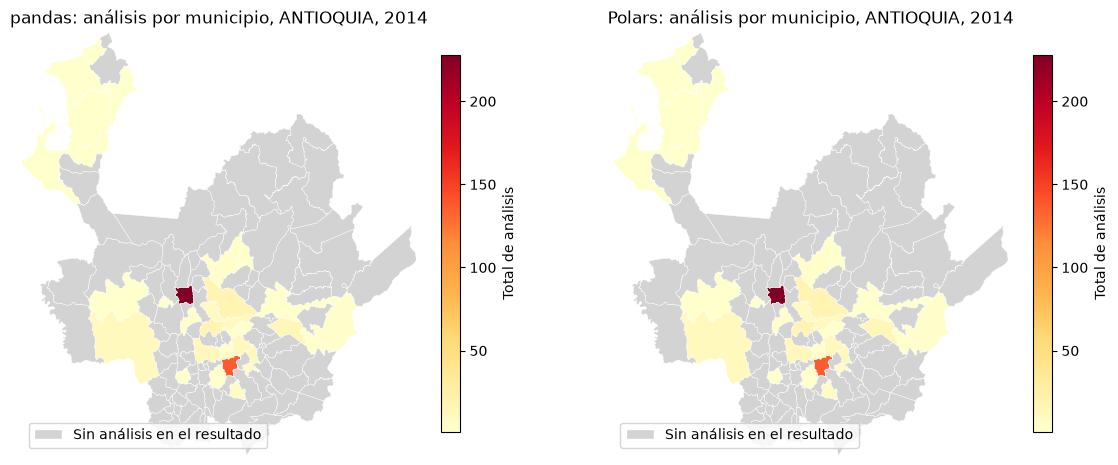

In [11]:
# Desarrollo
# Une ambos resultados a las mismas geometrías y comprueba tablas y mapas
from matplotlib.patches import Patch
municipios_geome = geometrias[["codigo_municipio", "geometry"]].copy()

print(municipios_geome.columns.tolist())
print(municipios_geome.shape, municipios_geome.crs)
print("Geometrías:", municipios_geome.geometry.notna().sum(), "| vacías:", municipios_geome.geometry.is_empty.sum())
print("Código único:", municipios_geome["codigo_municipio"].is_unique)
print("Cinco cifras:", municipios_geome["codigo_municipio"].str.fullmatch(r"[0-9]{5}").all())

resultado_map_pd = res_mem["pandas"].copy()
resultado_map_pl = res_mem["polars"].to_pandas()  

for nombre, r in [("pandas", resultado_map_pd), ("polars", resultado_map_pl)]:
    r["codigo_municipio"] = r["Código Municipio"].astype("string")
    print(nombre, r.shape, "| código único:", r["codigo_municipio"].is_unique, "| análisis:", r["total_analisis"].sum())

a = resultado_map_pd.sort_values("codigo_municipio").reset_index(drop=True)
b = resultado_map_pl.sort_values("codigo_municipio").reset_index(drop=True)

assert a["codigo_municipio"].tolist() == b["codigo_municipio"].tolist()
assert (a["total_analisis"].astype("int64") == b["total_analisis"].astype("int64")).all()
assert (a["ph_validos"].astype("int64") == b["ph_validos"].astype("int64")).all()
pd.testing.assert_series_equal(
    a["ph_media"].astype("float64"), b["ph_media"].astype("float64"),
    check_names=False, atol=0.000001, rtol=0,
)

# Une ambos resultados a las mismas geometrías y comprueba tablas y mapas.
pd_map = municipios_geome.merge(resultado_map_pd, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)
pl_map = municipios_geome.merge(resultado_map_pl, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)

for nombre, m, r in [("pandas", pd_map, resultado_map_pd), ("polars", pl_map, resultado_map_pl)]:
    sin_geome = r.loc[~r["codigo_municipio"].isin(municipios_geome["codigo_municipio"])]
    sin_resultado = m["_merge"].eq("left_only").sum()
    print(nombre, "| polígonos:", len(m), "| con resultado:", m["_merge"].eq("both").sum(),
          "| sin resultado:", sin_resultado, "| resultados sin geometría:", len(sin_geome))
    assert len(m) == len(municipios_geome)


depto_nombre = "ANTIOQUIA"
vmin = min(pd_map["total_analisis"].min(), pl_map["total_analisis"].min())
vmax = max(pd_map["total_analisis"].max(), pl_map["total_analisis"].max())

antioquia_pd = pd_map.loc[pd_map["codigo_municipio"].str.startswith(depto_elegido)]
antioquia_pl = pl_map.loc[pl_map["codigo_municipio"].str.startswith(depto_elegido)]
minx, miny, maxx, maxy = antioquia_pd.total_bounds

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, datos, motor in [(axes[0], antioquia_pd, "pandas"), (axes[1], antioquia_pl, "Polars")]:
    datos.plot(
        column="total_analisis", cmap="YlOrRd", vmin=vmin, vmax=vmax,
        legend=True, legend_kwds={"label": "Total de análisis", "shrink": 0.7},
        missing_kwds={"color": "lightgrey", "edgecolor": "white"},
        edgecolor="white", linewidth=0.3, ax=ax,
    )
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)
    ax.set_title(f"{motor}: análisis por municipio, {depto_nombre}, {anio_elegido}")
    ax.set_axis_off()
    ax.legend(handles=[Patch(facecolor="lightgrey", edgecolor="white", label="Sin análisis en el resultado")],
              loc="lower left")

plt.savefig(OUT /"comparacion_mapas.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**

_Se leyo directamente la capa municipios del GeoPackage de PD04. Tambien se mostaron las columnas, CRS y que la cantidad de geometrias son 1.122 en EPSG:4326. Luego se realizo la conversion del resultado agregado de polars con .to_pandas() después de medir. Por otro lado se unio por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante merge(..., how="left", validate="one_to_one"). Tambien se conservo el código como texto y se verifico antes de  la unicidad,y como resultado salieron 30 municipios y 517 analisis de antes de mapear, pero en la uniones no se tuvieron en 1092 poligonos sin resultados, 30 con resultados y nada en los resultados de geometria._

_Posteriormente se generaron dos mapas del departamento de "Antioquia" en el año 2014, uno para pandas y otro para polars, donde se  usaron la misma extensión, columna, límites de color, leyenda y tratamiento de ausentes. Además, estos dos mapas se guardaron en comparacion_mapas.png._ 

_Se tuvo en cuenta que las geometrías no participaban en el benchmark tabular ni se convirtieron a texto para medirlas con Polars. Además, La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Tambien se pudo comprobar que un mapa no sustituye una comparacion de valores, porque con lo visto en los resultados anteriores no me observa una diferencia clara entre los dos mapas, que utilizan un motor diferente_

## 6. Reejecución, evidencia y decisión · 45 minutos

Repite la construcción de los archivos en otra carpeta de ejecución nueva. No borres carpetas de datos originales ni reutilices un directorio particionado con archivos viejos. Comprueba contenido y total de registros; el nombre de los archivos o su hash no tiene por qué coincidir para que el contenido sea equivalente.

Guarda `mediciones.csv` con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida. Guarda aparte la ejecución inicial; calcula la mediana solo con las cinco repeticiones medidas. Añade inventario de bytes/archivos y controles de equivalencia.

Responde: ¿qué parte mejora con Parquet?, ¿cuándo ayuda la selección de particiones?, ¿qué diseño genera archivos demasiado pequeños?, ¿qué cambia entre tiempo en memoria y tiempo desde disco?, ¿qué elegirías para este conjunto y por qué?

**Control:** no presupongas que Polars o el particionamiento ganarán. Diferencias pequeñas o variables deben describirse como tales. El tamaño de un DataFrame no equivale a la memoria máxima del proceso.

In [12]:
# Desarrollo
# Concilia la segunda ejecución, exporta las mediciones y redacta la recomendación.
OUT = Path("OUT")
OUT.mkdir(parents=True, exist_ok=True)

EJEC2 = OUT / "EJECUCION2"
EJEC2.mkdir(parents=True, exist_ok=True)

EJECUCION2 = EJEC2 / ("ejecucion_" + datetime.now().strftime("%Y%m%d_%H%M%S") + "_b")
EJECUCION2.mkdir(parents=True, exist_ok=False)

proyeccion_pd.to_csv(EJECUCION2 / "proyeccion_completa.csv", index=False)
proyeccion_pd.to_parquet(EJECUCION2 / "proyeccion_completa.parquet", engine="pyarrow", compression="snappy", index=False)

inv2 = {}
for nombre, claves in [("por_anio", ["anio"]), ("por_anio_departamento", ["anio", "Código Departamento"])]:
    carpeta = EJECUCION2 / nombre
    carpeta.mkdir(parents=True, exist_ok=False)
    filas_inv = []
    for numero, (clave, grupo) in enumerate(proyeccion_pd.groupby(claves, dropna=False, sort=True)):
        clave = clave if isinstance(clave, tuple) else (clave,)
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        fila = dict(zip(claves, clave))
        fila.update({"archivo": str(archivo.relative_to(EJECUCION2)), "filas": len(grupo), "bytes": archivo.stat().st_size})
        filas_inv.append(fila)
    inv2[nombre] = pd.DataFrame(filas_inv)
    inv2[nombre].to_csv(EJECUCION2 / archivo_inv[nombre], index=False)

print("Segunda ejecución:", EJECUCION2)
print({k: len(v) for k, v in inv2.items()})

ref = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)

for nombre in ["por_anio", "por_anio_departamento"]:
    partes = [pd.read_parquet(EJECUCION2 / r, engine="pyarrow") for r in inv2[nombre]["archivo"]]
    rel = pd.concat(partes, ignore_index=True).sort_values("id_fila").reset_index(drop=True)
    assert len(rel) == len(datos_pd)
    assert rel["id_fila"].is_unique
    pd.testing.assert_frame_equal(ref, rel)
    assert inv2[nombre]["filas"].sum() == len(datos_pd)
    print(nombre, "- contenido y total equivalentes")

rel_unico = pd.read_parquet(EJECUCION2 / "proyeccion_completa.parquet", engine="pyarrow").sort_values("id_fila").reset_index(drop=True)
pd.testing.assert_frame_equal(ref, rel_unico)

rel_csv = pd.read_csv(EJECUCION2 / "proyeccion_completa.csv", dtype=tipos_pd).sort_values("id_fila").reset_index(drop=True)
pd.testing.assert_frame_equal(ref, rel_csv)

assert inv2["por_anio"]["filas"].tolist() == inventario_anio_leido["filas"].tolist()
assert inv2["por_anio_departamento"]["filas"].tolist() == inventario_anio_depto_leido["filas"].tolist()

inventario_bytes = pd.DataFrame([
    {"ejecucion": nombre_e, "diseno": d, "archivos": n, "bytes": b}
    for nombre_e, carpeta_e, inv in [("primera", EJECUCION, {"por_anio": inventario_anio_leido, "por_anio_departamento": inventario_anio_depto_leido}),
                                      ("segunda", EJECUCION2, inv2)]
    for d, n, b in (
        [("csv_unico", 1, (carpeta_e / "proyeccion_completa.csv").stat().st_size),
         ("parquet_unico", 1, (carpeta_e / "proyeccion_completa.parquet").stat().st_size)]
        + [(k, len(v), int(v["bytes"].sum())) for k, v in inv.items()]
    )
])
display(inventario_bytes)
inventario_bytes.to_csv(Path(OUT) / "inventario_bytes.csv", index=False)

version = {"pandas": pd.__version__, "polars": pl.__version__}
filas_res = {"pandas": len(res_mem["pandas"]), "polars": res_mem["polars"].height}
entrada_disco = {
    "unico": datos_pd,
    "por_anio": int(inventario_anio_leido.loc[inventario_anio_leido["anio"].eq(anio_elegido), "filas"].sum()),
    "por_anio_departamento": int(inventario_anio_depto_leido.loc[inventario_anio_depto_leido["anio"].eq(anio_elegido) & inventario_anio_depto_leido["Código Departamento"].eq(depto_elegido), "filas"].sum()),
}

m1 = tiempos.rename(columns={"corrida": "repeticion"}).assign(
    particionamiento="unico", filas_entrada=len(datos_pd), filas_salida=len(datos_pd))
m2 = t_mem.assign(operacion="consulta_memoria", formato="memoria", particionamiento="no_aplica",
                  filas_entrada=len(datos_pd), filas_salida=t_mem["motor"].map(filas_res))
m3 = t_disco.rename(columns={"variante": "particionamiento"}).assign(
    operacion="consulta_disco", formato="parquet")
m3["datos_pd"] = m3["particionamiento"].map(entrada_disco)
m3["filas_salida"] = m3["motor"].map(filas_res)
m4 = t_dif.assign(motor="polars", operacion="consulta_" + t_dif["modo"], formato="parquet",
                  particionamiento="unico", filas_entrada=len(datos_pd), filas_salida=filas_res["polars"]).drop(columns="modo")

todas = pd.concat([m1, m2, m3, m4], ignore_index=True)
todas["version"] = todas["motor"].map(version)
orden = ["motor", "version", "operacion", "formato", "particionamiento", "repeticion", "segundos", "filas_entrada", "filas_salida"]
todas = todas[orden]

iniciales = todas.loc[todas["repeticion"].astype(str).eq("inicial")]
medidas = todas.loc[todas["repeticion"].astype(str).ne("inicial")].copy()
medidas["repeticion"] = medidas["repeticion"].astype(int)

medidas.to_csv(Path(OUT) / "mediciones.csv", index=False)
iniciales.to_csv(Path(OUT) / "mediciones_iniciales.csv", index=False)
print(len(medidas), "mediciones |", len(iniciales), "iniciales")

claves = ["operacion", "formato", "particionamiento", "motor"]
assert (medidas.groupby(claves).size() == 5).all()

medianas = medidas.groupby(claves)["segundos"].agg(["median", "min", "max"]).reset_index()
display(medianas)

Segunda ejecución: OUT/EJECUCION2/ejecucion_20261022_212019_b
{'por_anio': 12, 'por_anio_departamento': 373}
por_anio - contenido y total equivalentes
por_anio_departamento - contenido y total equivalentes


,ejecucion,diseno,archivos,bytes
0,primera,csv_unico,1,2757904
1,primera,parquet_unico,1,830579
2,primera,por_anio,12,865700
3,primera,por_anio_departamento,373,2277000
4,segunda,csv_unico,1,2749330
5,segunda,parquet_unico,1,830579
6,segunda,por_anio,12,865700
7,segunda,por_anio_departamento,373,2277000


90 mediciones | 8 iniciales


,operacion,formato,particionamiento,motor,median,min,max
0,consulta_disco,parquet,por_anio,pandas,0.029758,0.027596,0.033190
1,consulta_disco,parquet,por_anio,polars,0.065335,0.047300,0.090807
2,consulta_disco,parquet,por_anio_departamento,pandas,0.026761,0.024341,0.029586
3,consulta_disco,parquet,por_anio_departamento,polars,0.051468,0.043605,0.104389
4,consulta_disco,parquet,unico,pandas,0.038159,0.035540,0.042599
5,consulta_disco,parquet,unico,polars,0.061159,0.046334,0.084109
6,consulta_escaneo,parquet,unico,polars,0.028791,0.027577,0.040745
7,consulta_lectura,parquet,unico,polars,0.035912,0.033586,0.043861
8,consulta_memoria,memoria,no_aplica,pandas,0.008545,0.006763,0.018198
9,consulta_memoria,memoria,no_aplica,polars,0.008769,0.007154,0.023093


**Interpretación:**

_Se repitio la contruccion de los archivos en otra carpeta de ejecucion nueva denominada "EJECUCION2". No se borraron las carpetas con datos originales y se comprobo el contenido y tatatla de registros. Tambien se guardo mediciones.csv con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida._ 

_Por otro lado se guardo la ejecucion inicial en mediciones_iniciales y se calculo la mediana solo con las cinco repeticiones medidad con se observa anteriormente. Tambien se añadio un inventario de bytes/archivos y controles de equivalencia._

**¿Qué parte mejora con Parquet?**
_Parquet mejora el tiempo de  analisis de grande cantidades de datos sea en  lectura o escritura de cualquiera de los dos motores utilizados, porque si se hiciera la lectura o escritura de un csv con pandas o polars, se nota la diferencia de tiempo para hacer esta actividades y lo anterior, se puede comprobar con lo desarrollado en este taller._
**¿Cuándo ayuda la selección de particiones?**
_La seleccion de particiones ayuda mucho, porque permite elegir un grupo de datos que tienen en comun una caracteristica como año, mes o departamento,que no permite diferenciarlos de la mayoria y esto reduce el tiempo que por ejemplo requiere pandas o polars para realizar una lectura o escritura._
**¿Qué diseño genera archivos demasiado pequeños?**
El diseño que generaba más archivos con parquet, fue cuando se utilizan año/departamento, porque se tenia que tener en cuenta las posibles combinaciones de 32 departamentos con años que comenzaban desde el 2014 hasta el 2025. 
**¿Qué cambia entre tiempo en memoria y tiempo desde disco?**
Lo principal que cambia entre tiempo en memoria y el tiempo desde disco,es que en memoria con pandas hay un menor tiempo de 0.0076s ,mientra  que en disco era de  0,036s, lo mismo paso en polars. Pero esta gran diferencia se debe a que en memoria se busco directamento solo filtrar y agregar informacion a las tablas existentes, mientras que en el caso del disco se tuvo que hacer el filtrado y la adiccion de informacion, además de compara el archivo único, los  archivos por año y los archivos por año/departamento, lo que hizo que fuera más lento.
**¿Qué elegirías para este conjunto y por qué?**
Yo elegiria usar parquet con el motor "polars" si estuviera haciendo una lectura o escritura de un archivo porque tomaria menos tiempo, pero en caso de necesitar consultar memoria o disco, seguiria utilizando parquet pero con pandas, porque en las pruebas se vio que necesita menos tiempo para realizar esos procesos.

## Entrega y referencias de API

`soluciones/PD05_particionamiento_pandas_polars.ipynb`, mediciones, inventarios, comparación cartográfica y controles regenerables en `kit/salidas/soluciones/PD05/`. Incluye una recomendación basada en resultados; no se califica obtener el menor tiempo.

- [pandas: escritura de archivos Parquet](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html)
- [Polars: fuentes y ejecución diferida](https://docs.pola.rs/user-guide/lazy/sources_sinks/)
- [Polars: scan_parquet](https://docs.pola.rs/api/python/stable/reference/api/polars.scan_parquet.html)

Usa las versiones fijadas por el curso; si la documentación más reciente muestra una opción diferente, comprueba su disponibilidad antes de usarla.